In [1]:
import sys,json,os,warnings
warnings.filterwarnings('ignore')
sys.path.insert(0,'../scripts')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,matplotlib.dates as mdates
from common import *
ACC="#20808D";MUTE="#9a9a94";INK="#2b2b2b";BAD="#C8452F"
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.edgecolor':MUTE,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK,'axes.titlesize':11.5,'axes.titleweight':'bold','axes.titlelocation':'left','figure.dpi':130,'savefig.bbox':'tight','lines.linewidth':2})
M='../outputs/metrics.json'
def save_metrics(k,v):
    d=json.load(open(M)) if os.path.exists(M) else {}
    d[k]=v;json.dump(d,open(M,'w'),indent=1,default=float)
pd.set_option('display.width',160)


# 2. Event study
Callaway-Sant'Anna ATT against never-subsidised states, each treated state counted equally. `Pre-specified` is the plan as written, with Chandigarh. `Headline` drops Chandigarh because its treatment is a petrol cap plus a subsidy.

In [2]:
p=load();pn=p[p.state!='CHANDIGARH']
gm=lambda d:d.dropna(subset=['gt']).groupby('state')['gt'].first().astype(int).to_dict()
c=sorted(p[p.group=='control'].state.unique());g=gm(p);gh=gm(pn)
rows=[];store={}
for nm,d,gg in [('Pre-specified, 7 states',p,g),('Headline, without Chandigarh',pn,gh)]:
  for y in ['share','logodds']:
    W=wide(d,y);s,a,b=event_study(W,gg,c);ev,r=boot(W,gg,c,n=999);lo,hi=np.nanpercentile(r[:,0],[2.5,97.5])
    R=rand_inf(W,gg,c,n=1999);ri=(np.abs(R[:,0])>=abs(a)).mean()
    rows.append(dict(run=nm,outcome=y,att_0_12=a,ci_lo=lo,ci_hi=hi,ri_p=ri,pre_m12_m2=s.loc[-12:-2].mean(),all_post=b))
    store[(nm,y)]=(s,np.nanpercentile(ev,[2.5,97.5],axis=0))
T=pd.DataFrame(rows).round(3);T.to_csv('../outputs/tables/main_results.csv',index=False);print(T.to_string())
h=T.iloc[2];l=T.iloc[3]
save_metrics('main',{'prespec_att':T.iloc[0].att_0_12,'att':h.att_0_12,'ci':[h.ci_lo,h.ci_hi],'ri_p':h.ri_p,'pre':h.pre_m12_m2,'lo_att':l.att_0_12,'lo_ci':[l.ci_lo,l.ci_hi],'lo_ri_p':l.ri_p,'lo_pre':l.pre_m12_m2})

                            run  outcome  att_0_12  ci_lo  ci_hi   ri_p  pre_m12_m2  all_post
0       Pre-specified, 7 states    share     2.003 -0.015  4.198  0.014      -0.766     3.145
1       Pre-specified, 7 states  logodds     0.102 -0.203  0.433  0.694      -0.270     0.141
2  Headline, without Chandigarh    share     1.061 -0.280  2.507  0.137      -0.887     2.455
3  Headline, without Chandigarh  logodds    -0.026 -0.267  0.256  0.926      -0.344     0.018


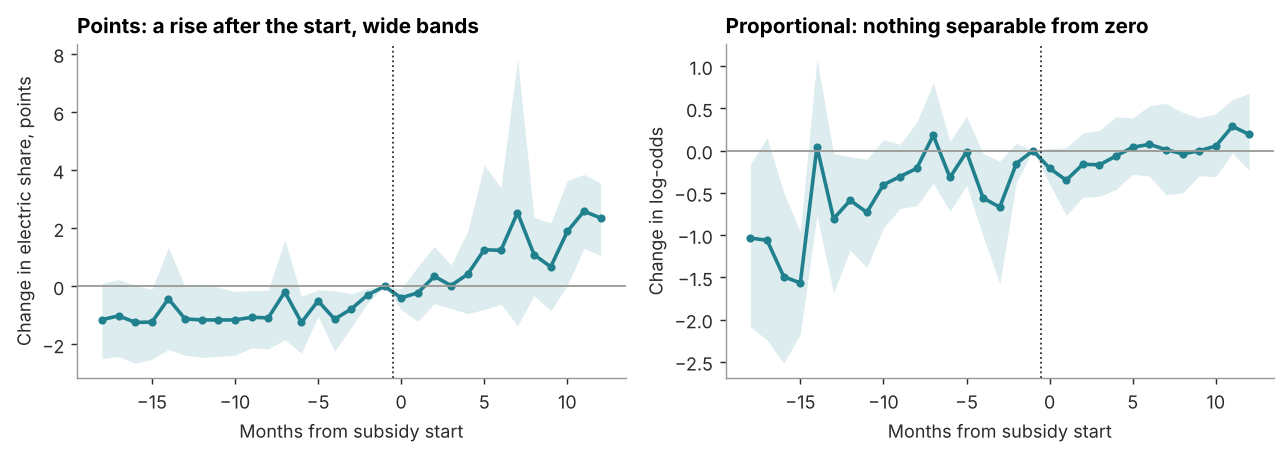

In [3]:
fig,axs=plt.subplots(1,2,figsize=(10,3.6))
for ax,y,t,yl in [(axs[0],'share','Points: a rise after the start, wide bands','Change in electric share, points'),(axs[1],'logodds','Proportional: nothing separable from zero','Change in log-odds')]:
    s,ci=store[('Headline, without Chandigarh',y)]
    ax.fill_between(s.index,ci[0],ci[1],color=ACC,alpha=.15,lw=0);ax.plot(s.index,s.values,color=ACC,marker='o',ms=3.5)
    ax.axhline(0,color=MUTE,lw=1);ax.axvline(-.5,color=INK,lw=1,ls=':');ax.set_title(t);ax.set_ylabel(yl);ax.set_xlabel('Months from subsidy start')
plt.tight_layout();plt.savefig('../outputs/charts/event_study.png',dpi=170);plt.show()
s,ci=store[('Headline, without Chandigarh','share')];pd.DataFrame({'event_month':s.index,'att':s.values,'lo':ci[0],'hi':ci[1]}).round(3).to_csv('../outputs/tables/event_study_share.csv',index=False)

## State by state
The average hides the spread. Each state is compared with the 17 controls on its own.

        state   start  att_points  pre_points  att_logodds
UTTAR PRADESH 2022-10       -0.97       -0.23        -0.43
 CHHATTISGARH 2022-09       -0.67       -2.75        -0.20
        DELHI 2020-08        0.45       -0.05         0.09
       ODISHA 2021-09        1.34       -0.49         0.12
  MAHARASHTRA 2021-07        2.00       -0.24         0.31
          GOA 2021-12        4.21       -1.55        -0.05


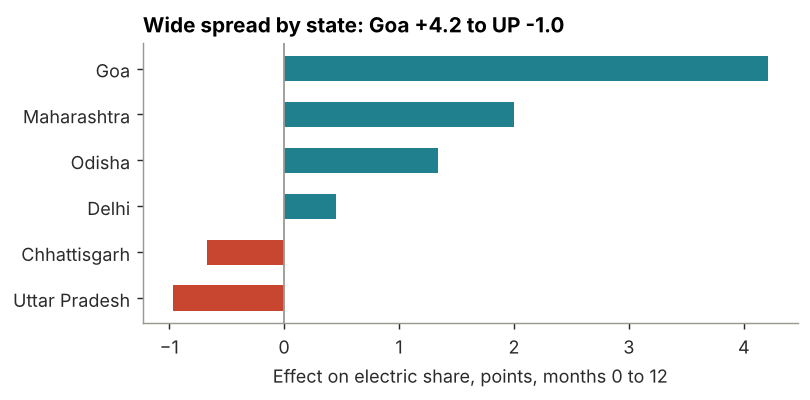

In [4]:
W=wide(pn,'share');L=wide(pn,'logodds');rs=[]
for k,v in gh.items():
    s,a,_=event_study(W,{k:v},c,leads=12);s2,a2,_=event_study(L,{k:v},c,leads=12)
    rs.append(dict(state=k,start=str(pn[pn.state==k].g.iloc[0])[:7],att_points=a,pre_points=s.loc[-12:-2].mean(),att_logodds=a2))
S=pd.DataFrame(rs).sort_values('att_points').round(2);S.to_csv('../outputs/tables/by_state.csv',index=False);print(S.to_string(index=False))
fig,ax=plt.subplots(figsize=(6.5,2.8));ax.barh(S.state.str.title(),S.att_points,color=[BAD if v<0 else ACC for v in S.att_points],height=.55)
ax.axvline(0,color=MUTE,lw=1);ax.set_xlabel('Effect on electric share, points, months 0 to 12');ax.set_title('Wide spread by state: Goa +4.2 to UP -1.0');plt.savefig('../outputs/charts/by_state.png');plt.show()
save_metrics('by_state',S.set_index('state').att_points.to_dict())

## Weighted by registrations
The headline counts each state equally, so Goa, about 1% of treated registrations, gets a sixth of the weight. This is the same state-level estimate weighted by two-wheeler registrations over months 0 to 12.

In [5]:
wt={k:pn[(pn.state==k)&(pn['t']>=v)&(pn['t']<=v+12)].regs_2w.sum() for k,v in gh.items()}
Sb=S.set_index('state');ws=pd.Series(wt)
wa=(Sb.att_points*ws).sum()/ws.sum();wa6=sum(event_study(W,{k:v},c,leads=12,base_k=6)[1]*wt[k] for k,v in gh.items())/ws.sum()
print(round(wa,3),round(wa6,3),(ws/ws.sum()).round(3).to_dict());save_metrics('weighted',{'att':wa,'att_base6':wa6,'goa_weight':ws['GOA']/ws.sum()})

0.285 0.683 {'CHHATTISGARH': 0.077, 'DELHI': 0.056, 'GOA': 0.009, 'MAHARASHTRA': 0.3, 'ODISHA': 0.091, 'UTTAR PRADESH': 0.466}


## Chandigarh without the two cap months
The spike could be removed without losing the state: February and March 2023 are blanked.

In [6]:
pb=p.copy();pb.loc[(pb.state=='CHANDIGARH')&(pb.date.isin(pd.to_datetime(['2023-02-01','2023-03-01']))),'share']=np.nan
Wb=wide(pb,'share');_s,ab,_=event_study(Wb,g,c);sc,ac,_=event_study(Wb,{'CHANDIGARH':g['CHANDIGARH']},c,leads=12);print(round(ab,3),round(ac,3));save_metrics('chandigarh_blanked',{'seven_state':ab,'alone':ac})

1.237 2.881


## Counterfactual scale
What share would treated states have had, on the estimate?

In [7]:
W=wide(pn,'share');vals=[]
for k,v in gh.items(): vals.append(W.loc[k,[t for t in W.columns if v<=t<=v+12]].mean())
ob=np.mean(vals);save_metrics('scale',{'treated_mean_share_0_12':ob});print(round(ob,2))

4.55


## Two-way fixed effects, for comparison
Biased under staggered timing and growing effects. Shown because reviewers expect it.

In [8]:
import pyfixest as pf
r=[]
for nm,d in [('Pre-specified',p),('Headline',pn)]:
  for y in ['share','logodds']:
    f=pf.feols(f'{y}~post|state+t',data=d.dropna(subset=[y]),vcov={'CRV1':'state'});r.append(dict(run=nm,y=y,coef=f.coef().iloc[0],se=f.se().iloc[0]))
for y in ['share']:
    q=pn[(pn['gt'].isna())|(pn['t']<=pn['gt']+12)].dropna(subset=[y]);f=pf.feols(f'{y}~post|state+t',data=q,vcov={'CRV1':'state'});r.append(dict(run='Headline, months 0 to 12 only',y=y,coef=f.coef().iloc[0],se=f.se().iloc[0]))
r=pd.DataFrame(r).round(3);r.to_csv('../outputs/tables/twfe.csv',index=False);print(r);save_metrics('twfe',r.to_dict('records'))

                             run        y   coef     se
0                  Pre-specified    share  3.882  1.309
1                  Pre-specified  logodds  0.684  0.284
2                       Headline    share  3.390  1.366
3                       Headline  logodds  0.626  0.301
4  Headline, months 0 to 12 only    share  1.947  1.074


## Library cross-check
The hand-written estimator is checked against the `csdid` package on group-time effects.

In [9]:
from csdid.att_gt import ATTgt
d=pn.copy();d['id']=d.state.astype('category').cat.codes;d['gv']=d['gt'].fillna(0).astype(int)+d['gt'].notna().astype(int);d['tt']=d['t']+1
d['share']=d.share.fillna(0)
o=ATTgt(yname='share',gname='gv',idname='id',tname='tt',data=d[['share','gv','id','tt']],control_group='nevertreated',est_method='reg').fit(est_method='reg',base_period='universal',bstrap=False)
res=o.summ_attgt().summary2
res=res.rename(columns=lambda x:x.strip())
gc=[c_ for c_ in res.columns if c_.lower() in('group',)][0];tc=[c_ for c_ in res.columns if c_.lower() in('time',)][0];ac=[c_ for c_ in res.columns if 'att' in c_.lower()][0]
res=res[[gc,tc,ac]].astype(float);res=res[(res[tc]>=res[gc])&(res[tc]<=res[gc]+12)]
lib=res.groupby(gc)[ac].mean();w=d.groupby('gv').id.nunique();w=w[w.index>0]
lib_att=(lib*w.reindex(lib.index)).sum()/w.reindex(lib.index).sum()
Y0=wide(pn.assign(share=pn.share.fillna(0)),'share');own=event_study(Y0,gh,c)[1]
print(round(lib_att,3),round(own,3));save_metrics('csdid',{'lib':lib_att,'own':own})

1.061 1.061
